In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

dir_path = 'output/Experiment_7'


In [36]:
training_results=pd.read_csv(os.path.join(dir_path, 'reuslts_trained.csv'))
test_episodes=pd.read_csv(os.path.join(dir_path, 'training_results.csv'))
results_trained =pd.read_csv(os.path.join(dir_path, 'test_episodes.csv'))
step_test=pd.read_csv(os.path.join(dir_path, 'step_test.csv'),nrows=12)
res_test = pd.read_csv(os.path.join(dir_path,'res_test.csv'))

## HEATMAP REWARD

                      score  accuracy_tot  training_time_tot  total_energy_tot
score              1.000000      0.476243           0.311577          0.038068
accuracy_tot       0.476243      1.000000           0.740789          0.524212
training_time_tot  0.311577      0.740789           1.000000          0.757520
total_energy_tot   0.038068      0.524212           0.757520          1.000000


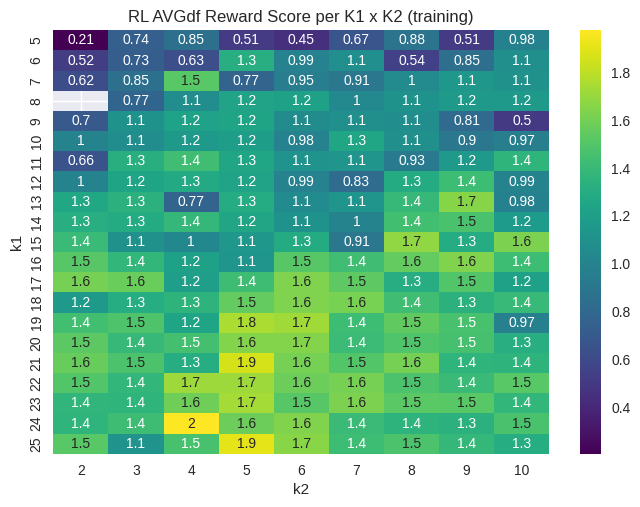

In [43]:


# 1. Correlazione tra componenti e reward
print(training_results[['score', 'accuracy_tot', 'training_time_tot', 'total_energy_tot']].corr())



# 3. Heatmap reward in funzione di k1 e k2
pivot = training_results.pivot_table(index="k1", columns="k2", values="score", aggfunc="mean")
sns.heatmap(pivot, annot=True, cmap="viridis")
plt.title("RL AVGdf Reward Score per K1 x K2 (training)")


plt.savefig('img/reward_heatmap_training.png',bbox_inches="tight")
plt.show()

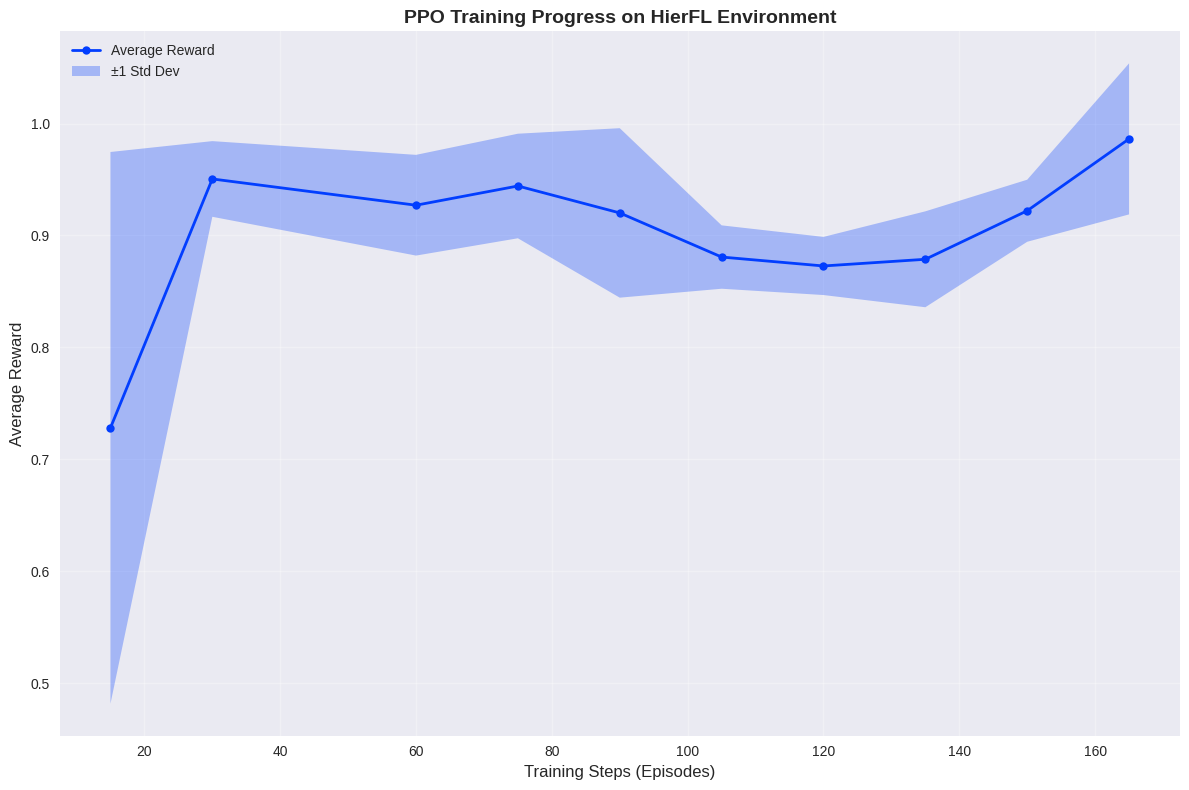

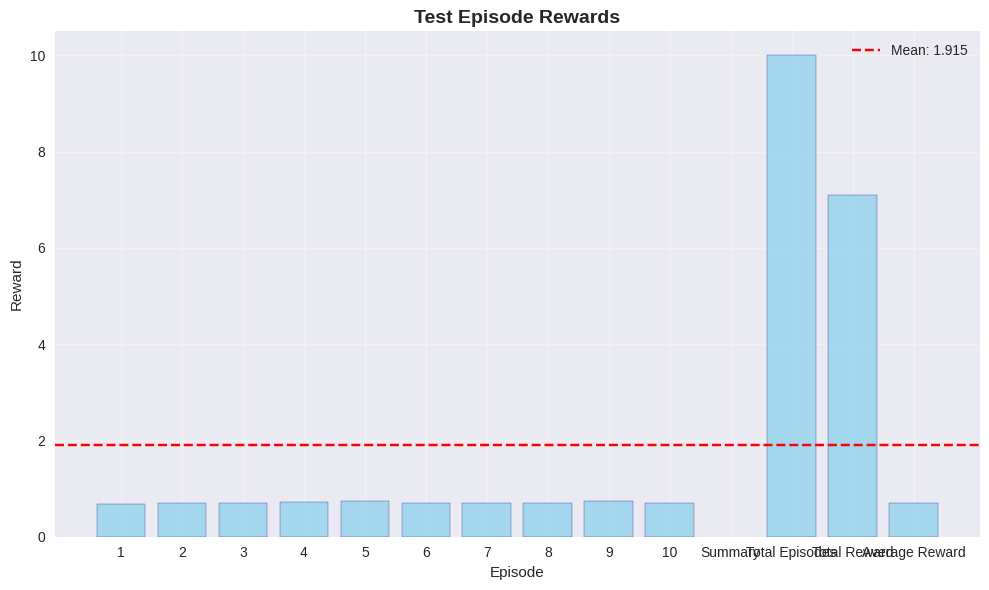

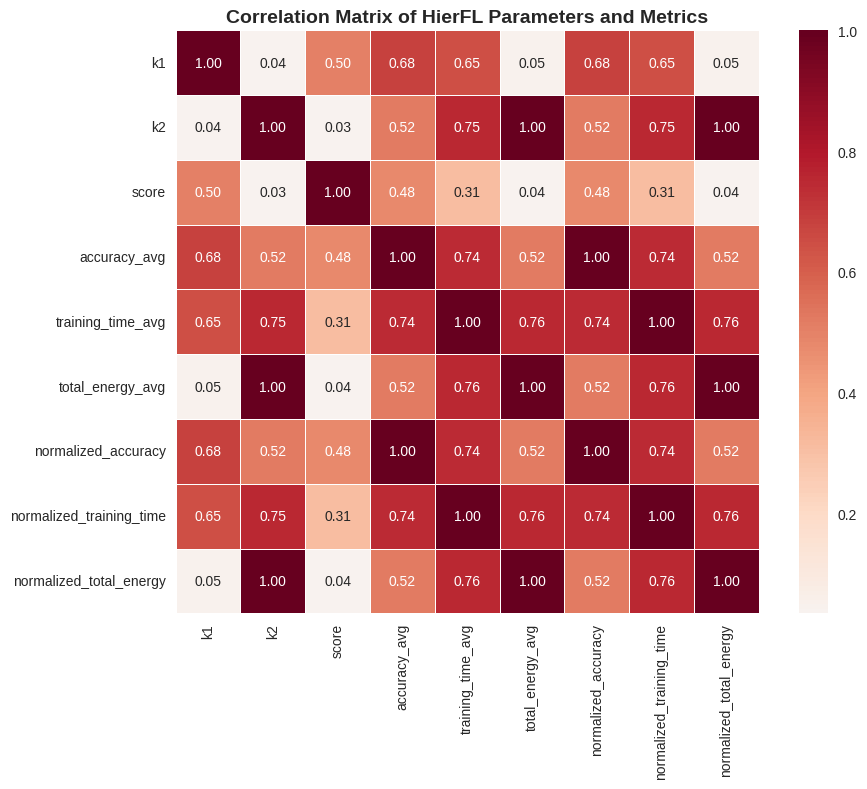

In [5]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.patches import Patch

# Set style for better-looking plots
plt.style.use('seaborn-v0_8')
sns.set_palette("bright")



# Load all CSV files
training_results = pd.read_csv(os.path.join(dir_path, 'training_results.csv'))
test_episodes = pd.read_csv(os.path.join(dir_path, 'test_episodes.csv'))
results_trained = pd.read_csv(os.path.join(dir_path, 'reuslts_trained.csv'))  # corretto da "reuslts_trained.csv"
step_test = pd.read_csv(os.path.join(dir_path, 'step_test.csv'))
res_test = pd.read_csv(os.path.join(dir_path, 'res_test.csv'), nrows=11)

# 1. Training Progress with Confidence Intervals
fig, ax = plt.subplots(1, 1, figsize=(12, 8))
training_results['AvgReward'] = training_results['AvgReward'].astype(float)/5 #FOR 1 EPISODE
ax.plot(training_results['Step'], training_results['AvgReward'], 
        marker='o', linewidth=2, markersize=6, label='Average Reward')
ax.fill_between(training_results['Step'],
                training_results['AvgReward'] - training_results['StdDevReward'],
                training_results['AvgReward'] + training_results['StdDevReward'],
                alpha=0.3, label='±1 Std Dev')
ax.set_title('PPO Training Progress on HierFL Environment', fontsize=14, fontweight='bold')
ax.set_xlabel('Training Steps (Episodes)', fontsize=12)
ax.set_ylabel('Average Reward', fontsize=12)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig('img/training_progress.png')

plt.show()

# 2. Test Episode Rewards Distribution
fig, ax1 = plt.subplots(1, 1, figsize=(10, 6))

ax1.bar(test_episodes['Episode'], test_episodes['Reward'], 
        color='skyblue', alpha=0.7, edgecolor='navy')
ax1.axhline(y=test_episodes['Reward'].mean(), color='red', 
           linestyle='--', label=f'Mean: {test_episodes["Reward"].mean():.3f}')
ax1.set_title('Test Episode Rewards', fontsize=14, fontweight='bold')
ax1.set_xlabel('Episode')
ax1.set_ylabel('Reward')
ax1.grid(True, alpha=0.3)
ax1.legend()
plt.tight_layout()

plt.savefig('img/test_episode_rewards.png')
plt.show()

# 4. Correlation Heatmap
fig, ax = plt.subplots(1, 1, figsize=(10, 8))

# Select numerical columns for correlation
corr_cols = ['k1', 'k2', 'score', 'accuracy_avg', 'training_time_avg', 
            'total_energy_avg', 'normalized_accuracy', 'normalized_training_time', 
            'normalized_total_energy']

correlation_matrix = results_trained[corr_cols].corr()

# Create heatmap
sns.heatmap(correlation_matrix, annot=True, cmap='RdBu_r', center=0,
           square=True, linewidths=0.5, ax=ax, fmt='.2f')
ax.set_title('Correlation Matrix of HierFL Parameters and Metrics', 
            fontsize=14, fontweight='bold')
plt.tight_layout()

plt.savefig('img/correlation_heatmap.png')
plt.show()

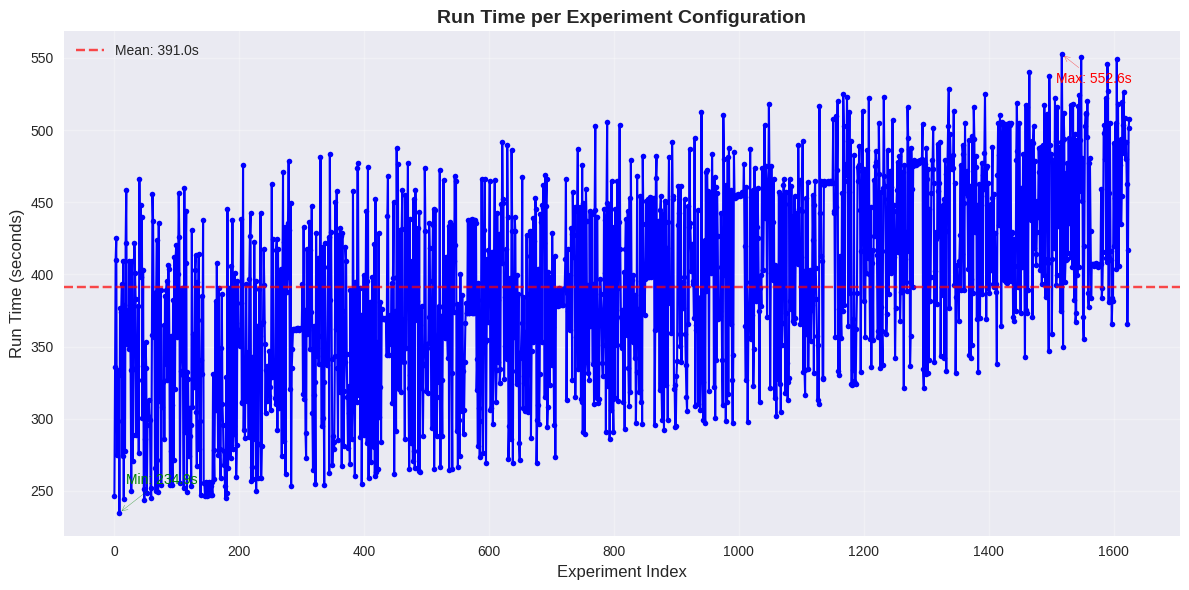

=== RUNTIME STATISTICS ===
Total experiments: 1626
Mean runtime: 391.02 seconds (6.5 minutes)
Std deviation: 69.12 seconds
Min runtime: 234.89 seconds (3.9 minutes)
Max runtime: 552.56 seconds (9.2 minutes)
Total experimental time: 176.6 hours


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Carica il file CSV
df_time = pd.read_csv(os.path.join(dir_path,'time.csv'))

# Crea il grafico
plt.figure(figsize=(12, 6))
plt.plot(df_time.index, df_time['run_time'], marker='o', linestyle='-', 
         color='blue', markersize=4, linewidth=1.5)
plt.title('Run Time per Experiment Configuration', fontsize=14, fontweight='bold')
plt.xlabel('Experiment Index', fontsize=12)
plt.ylabel('Run Time (seconds)', fontsize=12)
plt.grid(True, alpha=0.3)

# Aggiungi statistiche utili
mean_time = df_time['run_time'].mean()
plt.axhline(y=mean_time, color='red', linestyle='--', alpha=0.7, 
            label=f'Mean: {mean_time:.1f}s')

# Aggiungi annotazioni per min e max
min_time = df_time['run_time'].min()
max_time = df_time['run_time'].max()
min_idx = df_time['run_time'].idxmin()
max_idx = df_time['run_time'].idxmax()

plt.annotate(f'Min: {min_time:.1f}s', 
             xy=(min_idx, min_time), xytext=(min_idx+10, min_time+20),
             arrowprops=dict(arrowstyle='->', color='green', alpha=0.7),
             fontsize=10, color='green')

plt.annotate(f'Max: {max_time:.1f}s', 
             xy=(max_idx, max_time), xytext=(max_idx-10, max_time-20),
             arrowprops=dict(arrowstyle='->', color='red', alpha=0.7),
             fontsize=10, color='red')

plt.legend()
plt.tight_layout()
plt.savefig('img/runtime_per_experiment.png')
plt.show()

# Stampa statistiche riassuntive
print("=== RUNTIME STATISTICS ===")
print(f"Total experiments: {len(df_time)}")
print(f"Mean runtime: {mean_time:.2f} seconds ({mean_time/60:.1f} minutes)")
print(f"Std deviation: {df_time['run_time'].std():.2f} seconds")
print(f"Min runtime: {min_time:.2f} seconds ({min_time/60:.1f} minutes)")
print(f"Max runtime: {max_time:.2f} seconds ({max_time/60:.1f} minutes)")
print(f"Total experimental time: {df_time['run_time'].sum()/3600:.1f} hours")
